
# DS5020 Mini-Project #01: Customers Like You
## PCA vs TruncatedSVD for Retail Product Recommendations

**Student:** Vaenkatakrishnan Srinivasan  
**Course:** DS5020  
**Project Type:** Individual  
**Roles:** Data Engineer and Machine Learning Engineer

### Project Overview

This project develops a personalized product recommendation system using the UCI Online Retail II dataset.

The project uses TruncatedSVD to reduce the dimensionality of a sparse customer-product purchase matrix and cosine similarity to recommend products based on customer purchasing behavior.

The primary objectives are to:

- Build a clean, sparse customer-product matrix.
- Compare PCA and TruncatedSVD.
- Generate top-10 product recommendations.
- Evaluate recommendations against a bestseller baseline.
- Analyze customer segments using dimensionality reduction and clustering.

**Selected Model:** TruncatedSVD with 50 components.

**Random Seed:** 42.


In [1]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import load_npz
from IPython.display import display, Image

current_dir = Path.cwd()

if (current_dir / "outputs").exists():
    project_dir = current_dir
else:
    project_dir = current_dir.parent

output_dir = project_dir / "outputs"

print("Project directory:", project_dir)
print("Outputs folder exists:", output_dir.exists())


Project directory: c:\Users\venki\Downloads\DS5020-MiniProject01
Outputs folder exists: True



## 1. Dataset Loading and Data Cleaning (DE1–DE2)

### Dataset

The project uses the UCI Online Retail II dataset, containing transactions from two Excel worksheets.

The original dataset contains 1,067,371 transactions and 8 columns.

### Data Cleaning

The dataset was cleaned by removing:

- Cancelled invoices.
- Transactions with non-positive quantities.
- Transactions with non-positive prices.
- Non-product transaction codes.
- Transactions without customer IDs.

Cleaning decisions were made to ensure that only valid, identifiable product purchases were used for the recommendation system.

After cleaning, 802,664 transactions remained.

The table below shows the cleaning results generated by `build_matrix.py`.


In [2]:

cleaning_log = pd.read_csv(output_dir / "cleaning_log.csv")

print("Data Cleaning Log")
display(cleaning_log)


Data Cleaning Log


,Cleaning Step,Rows Removed,Rows Remaining
0,Cancelled invoices,19494,1047877
1,Non-positive quantities,3457,1044420
2,Non-positive prices,2750,1041670
3,Non-product codes,4551,1037119
4,Missing Customer IDs,234455,802664
5,Missing Descriptions,0,802664



## 2. Time-Based Split and Sparse Matrix (DE3–DE5)

### Time-Based Train/Test Split (DE3)

The cleaned dataset was split chronologically to prevent future purchases from being used during model training.

The split cutoff was October 9, 2011, at 12:50.

- Training transactions: 684,101
- Test transactions: 118,563
- Eligible held-out purchase rows: 52,582
- Eligible evaluation customers: 1,916

Only training transactions were used to construct the customer-product matrix and fit the dimensionality reduction models.

### Customer-Product Matrix (DE4)

A binary customer-product matrix was constructed using a Compressed Sparse Row (CSR) representation.

- Rows represent customers.
- Columns represent products.
- A value of 1 indicates a purchase during training.
- A value of 0 indicates no recorded purchase.

### Matrix Statistics (DE5)

The matrix is highly sparse because customers purchase only a small fraction of the available products.

We compare its sparse storage size with the memory required for a dense float32 representation.


In [3]:

split_summary = pd.read_csv(output_dir / "split_summary.csv")

print("Time-Based Train/Test Split")
display(split_summary)

X = load_npz(output_dir / "customer_product_matrix.npz")

rows, cols = X.shape
nonzeros = X.nnz
sparsity = (1 - nonzeros / (rows * cols)) * 100

dense_size_mib = rows * cols * 4 / (1024 ** 2)
sparse_size_mib = (
    X.data.nbytes + X.indices.nbytes + X.indptr.nbytes
) / (1024 ** 2)

matrix_stats = pd.DataFrame({
    "Metric": [
        "Customers",
        "Products",
        "Nonzero entries",
        "Sparsity (%)",
        "Dense float32 size (MiB)",
        "CSR matrix size (MiB)"
    ],
    "Value": [
        rows,
        cols,
        nonzeros,
        round(sparsity, 2),
        round(dense_size_mib, 2),
        round(sparse_size_mib, 2)
    ]
})

print("\nCustomer-Product Matrix Statistics")
display(matrix_stats)


Time-Based Train/Test Split


,Metric,Value
0,First transaction,2009-12-01 07:45:00
1,Last transaction,2011-12-09 12:50:00
2,Train/Test cutoff,2011-10-09 12:50:00
3,Training rows,684101
4,Testing rows,118563
5,Eligible test rows,52582
6,Eligible test customers,1916
7,Eligible test products,2674



Customer-Product Matrix Statistics


,Metric,Value
0,Customers,5474.00
1,Products,4534.00
2,Nonzero entries,417742.00
3,Sparsity (%),98.32
4,Dense float32 size (MiB),94.68
5,CSR matrix size (MiB),3.21



## 3. Dimensionality Reduction (ML1–ML2)

### Method Selection (ML1)

TruncatedSVD was selected as the primary dimensionality reduction method because the customer-product matrix is 98.32% sparse.

Unlike standard PCA, TruncatedSVD can operate directly on sparse data without converting the matrix into a dense representation.

TruncatedSVD reduces the original 4,534 product dimensions into a smaller number of components while preserving important purchasing patterns.

### Component Experiments (ML2)

TruncatedSVD was evaluated using:

**k = 10, 20, 50, 100, 200**

For each value of k, explained variance and relative Frobenius reconstruction error were measured.

As k increases, reconstruction error decreases, but the model requires more components.

### Selected Model

**TruncatedSVD with k = 50** was selected because it achieved the same held-out Hit Rate@10 as k = 100 while using fewer components.

The final choice balances recommendation performance and model compactness.


TruncatedSVD Component Experiments


,Components,Explained Variance(%),Training Time(seconds),Relative Reconstruction Error
0,10,15.27,0.05,0.8989
1,20,19.34,0.08,0.8770
2,50,27.10,0.15,0.8337
3,100,35.73,0.48,0.7828
4,200,47.91,1.29,0.7047


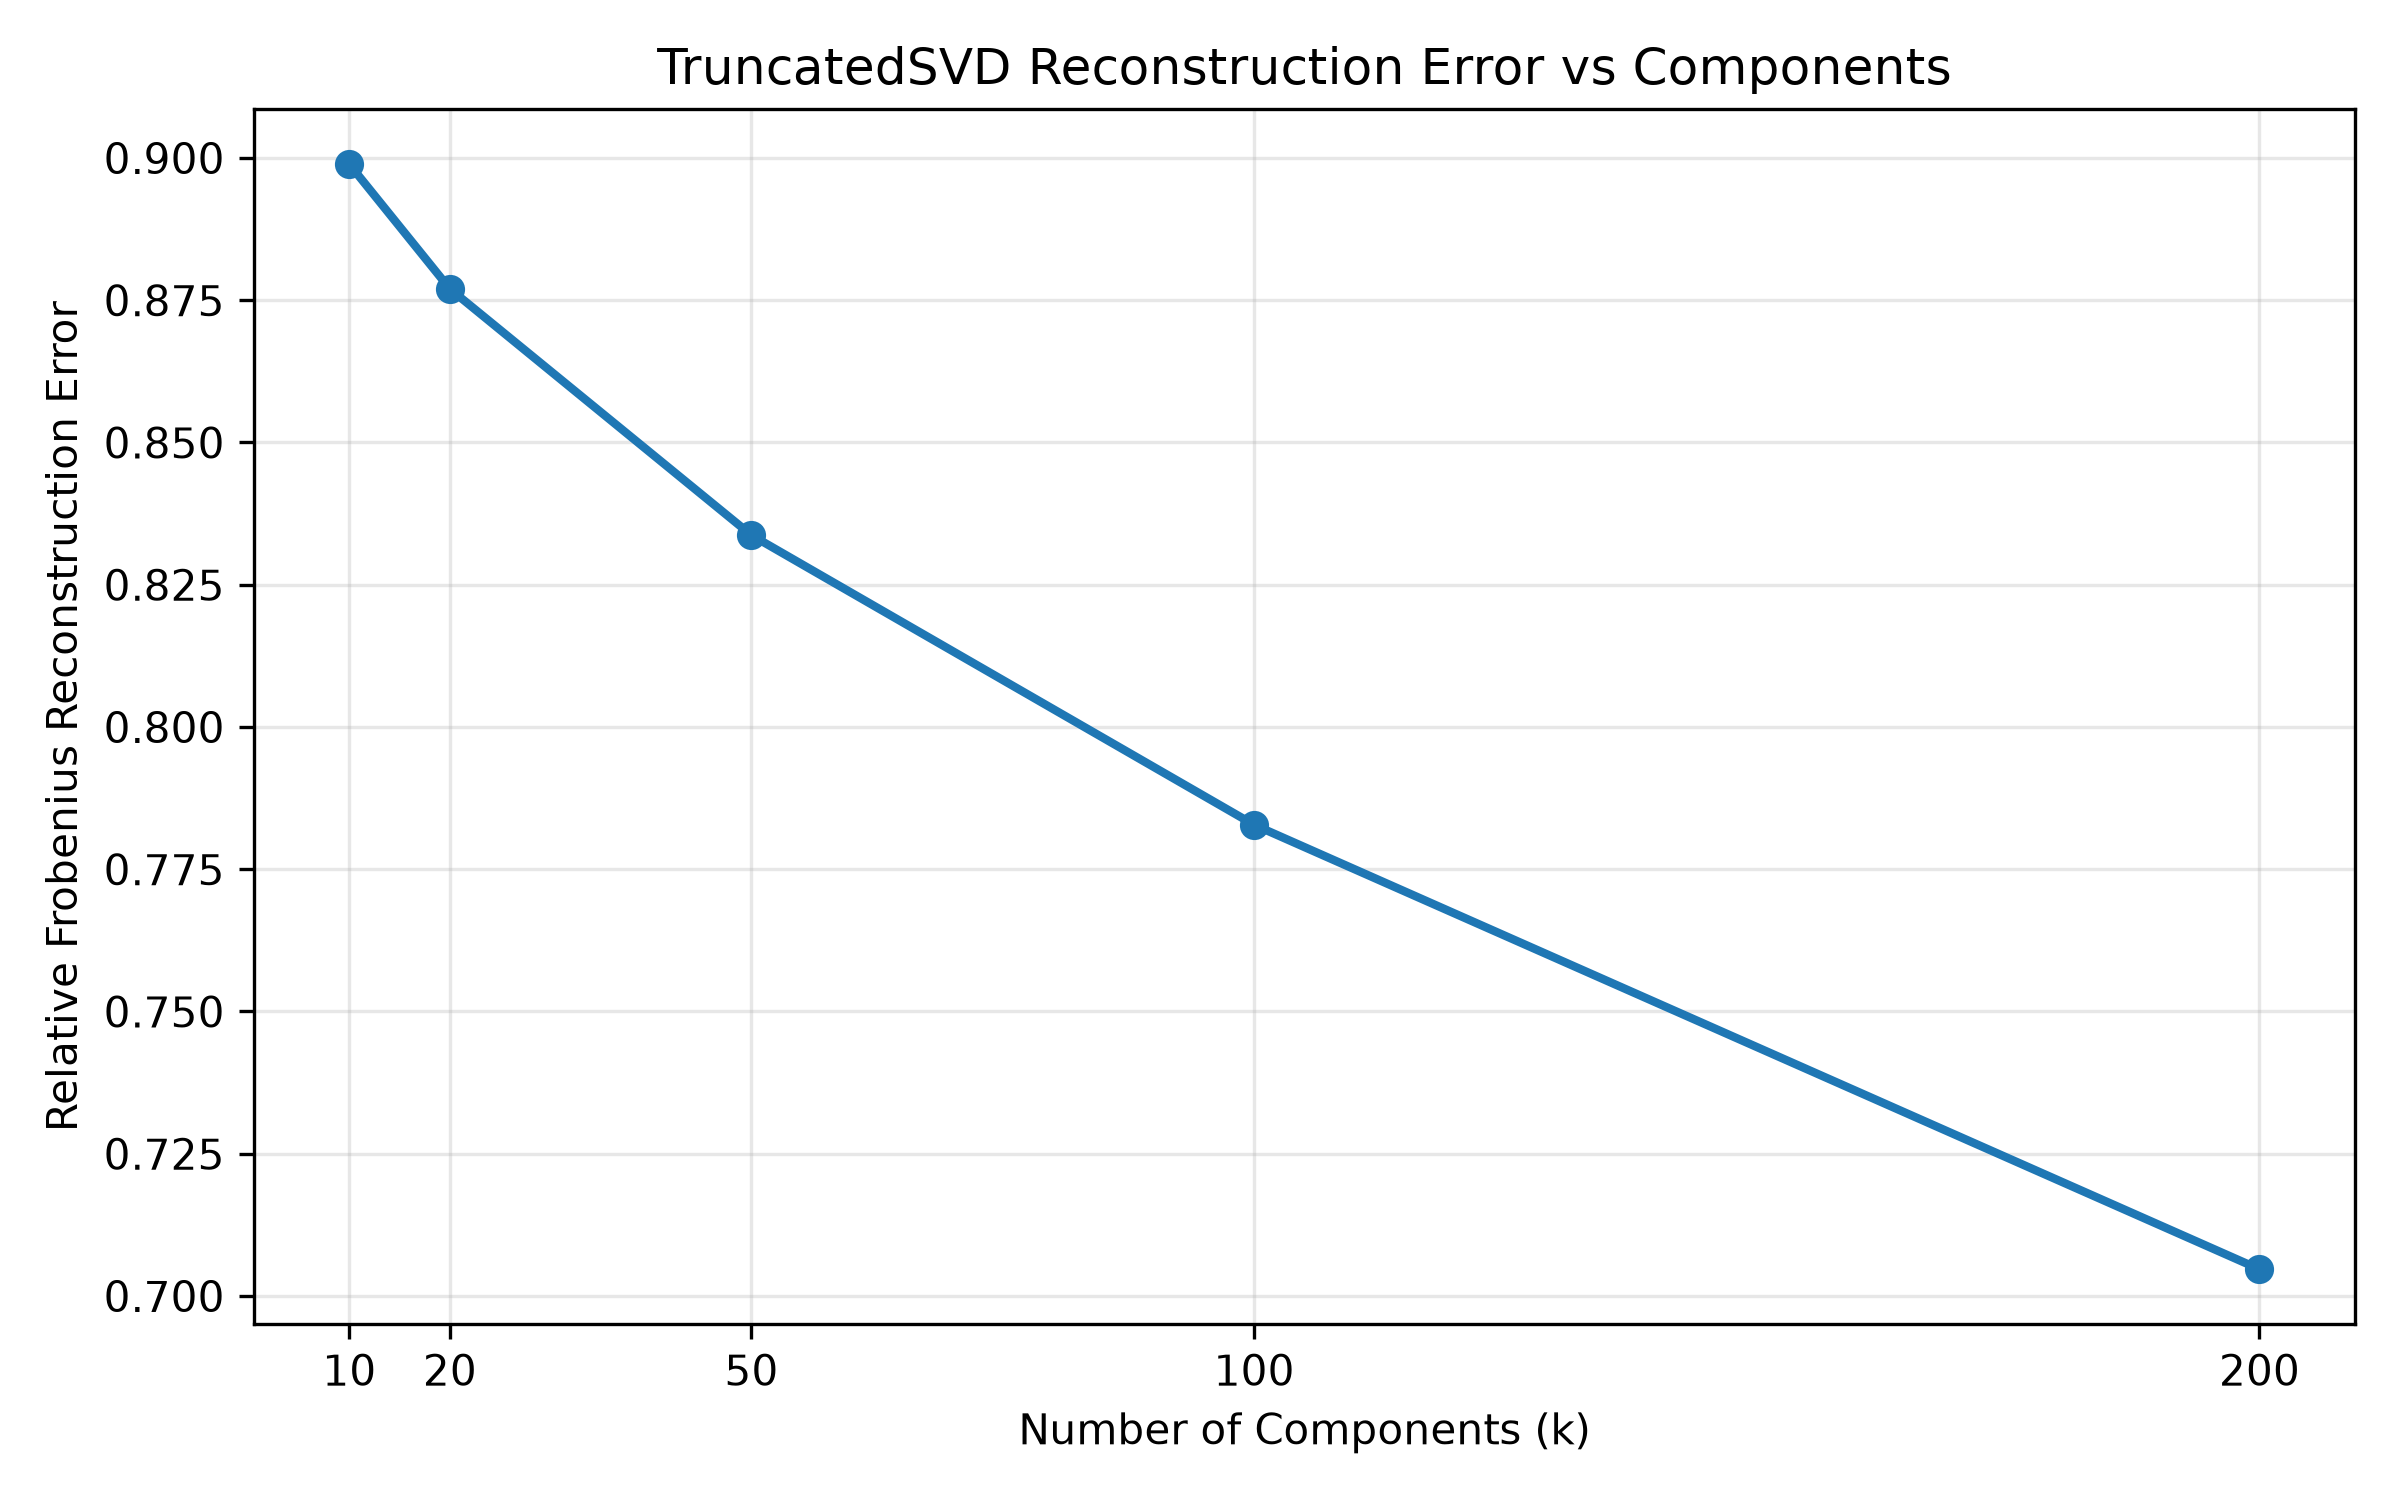

In [4]:

svd_results = pd.read_csv(output_dir / "svd_results.csv")

print("TruncatedSVD Component Experiments")
display(svd_results)

display(Image(filename=str(output_dir / "svd_reconstruction_error.png")))



## 4. Product Recommendations and Evaluation (ML3–ML4)

### Cosine Similarity Recommendations (ML3)

Product recommendations were generated using TruncatedSVD with 50 components and cosine similarity.

The recommendation process:

1. Represents each product using its 50-dimensional SVD factor vector.
2. Finds the 10 most similar products using cosine similarity.
3. Scores candidate products based on similarity to products previously purchased by a customer.
4. Excludes products the customer already purchased.
5. Uses a bestseller fallback when necessary to complete the top-10 recommendations.

The final model generated 54,740 recommendations for 5,474 customers, with 10 recommendations per customer.

Validation confirmed that no previously purchased products appeared in the recommendation lists.

### Held-Out Evaluation (ML4)

The model was evaluated using Hit Rate@10 on 1,916 eligible customers.

A hit occurs when at least one of the customer's 10 recommendations matches a previously unseen product purchased during the held-out test period.

The model was compared against a bestseller baseline that recommends popular products not previously purchased by each customer.

### Results

- Selected model: TruncatedSVD, k = 50
- Model Hit Rate@10: 30.32%
- Bestseller Hit Rate@10: 26.83%
- Improvement: 3.49 percentage points
- Nightly recommendation job runtime: 2.27 seconds

The selected model outperformed the bestseller baseline on the held-out evaluation.


In [5]:

evaluation_results = pd.read_csv(output_dir / "evaluation_results.csv")

print("Hit Rate@10 Evaluation Results")
display(evaluation_results)

recommendations = pd.read_csv(
    output_dir / "cosine_recommendations_50.csv"
)

print("\nRecommendation Summary")
print("Total recommendations:", len(recommendations))
print("Expected customers:", X.shape[0])
print("Recommendations per customer:", len(recommendations) // X.shape[0])

print("\nExample: First Customer's Top-10 Recommendations")
display(recommendations.head(10).drop(
    columns=["customer_id", "CustomerID", "Customer ID"],
    errors="ignore"
))


Hit Rate@10 Evaluation Results


,Model,Components,Hit Rate@10 (%),Customers Hit,Evaluation Time (seconds)
0,Bestseller Baseline,0,26.83,514,NaN
1,TruncatedSVD Cosine,10,27.51,527,0.89
2,TruncatedSVD Cosine,20,29.96,574,1.32
3,TruncatedSVD Cosine,50,30.32,581,1.27
4,TruncatedSVD Cosine,100,30.32,581,1.56
5,TruncatedSVD Cosine,200,27.30,523,1.32
6,PCA Cosine,50,30.32,581,1.13



Recommendation Summary
Total recommendations: 54740
Expected customers: 5474
Recommendations per customer: 10

Example: First Customer's Top-10 Recommendations


,Customer Index,Rank,Product,Cosine Score
0,0,1,48194,8.902355
1,0,2,48184,8.117018
2,0,3,48116,6.467898
3,0,4,48129,6.449659
4,0,5,85014A,4.179629
5,0,6,85014B,4.119003
6,0,7,85014C,3.179703
7,0,8,85014D,2.944452
8,0,9,48189,2.885861
9,0,10,15060B,2.487671



## 5. PCA vs TruncatedSVD Comparison (ML5)

### Objective

This experiment compares PCA and TruncatedSVD using 50 components on the same customer-product training matrix.

The comparison considers:

- Model fitting time.
- Memory usage during fitting.
- Explained variance.
- Reconstruction error.
- Held-out recommendation Hit Rate@10.

### Method Comparison

**PCA** centers the data before dimensionality reduction. Standard PCA requires a dense representation of the customer-product matrix.

**TruncatedSVD** does not require centering and can work directly with the sparse CSR matrix.

This makes TruncatedSVD particularly suitable for sparse recommendation datasets.

### Key Findings

- TruncatedSVD fitting time: approximately 0.19 seconds.
- PCA fitting time: approximately 0.34 seconds.
- TruncatedSVD explained variance: 27.10%.
- PCA explained variance: 27.17%.
- Both methods achieved a Hit Rate@10 of 30.32%.

The measured Python allocation peaks were approximately 4.91 MB for TruncatedSVD and 99.53 MB for PCA. These measurements were collected using `tracemalloc` and do not represent complete process memory usage.

### Decision

**TruncatedSVD with 50 components** was selected because it supports sparse input directly, has a lower measured fitting time, and achieved the same recommendation Hit Rate@10 as PCA.


In [6]:

comparison_results = pd.read_csv(
    output_dir / "pca_svd_comparison.csv"
)

print("PCA vs TruncatedSVD Comparison (k = 50)")
display(comparison_results)


PCA vs TruncatedSVD Comparison (k = 50)


,Method,Components,Fit Time (seconds),Python Peak Memory (MB),Stored Factors (MB),Explained Variance (%),Relative Reconstruction Error
0,TruncatedSVD,50,0.1893,4.91,1.91,27.10,0.8337
1,PCA,50,0.2675,99.53,1.93,27.17,NaN



### PCA vs. Truncated SVD — Comparison Table

| Measure | PCA | Truncated SVD |
|---|---|---|
| k used | 50 | 50 |
| Fit time (seconds) | 0.3389 | 0.1946 |
| Peak memory during fit (MB) | 99.53 | 4.91 |
| Size of stored factors (MiB) | 1.93 | 1.91 |
| Variance explained or relative reconstruction error | 27.17% explained variance | 27.10% explained variance; 0.8337 relative reconstruction error |
| Hit rate at 10 on held-out purchases | 30.32% | 30.32% |
| Best-seller baseline hit rate at 10 | 26.83% | 26.83% |
| What component 1 represents, in words | Strongest variation in purchasing behavior relative to the average customer | Broad purchasing-activity pattern associated with frequently purchased products |

**Memory measurement note:** Peak memory values are based on Python `tracemalloc` measurements, not full-process memory usage. The dense conversion required for PCA occurred before memory tracking began.

**Conclusion:** Both methods achieved the same Hit Rate@10, but Truncated SVD was faster in the recorded run and works directly with the sparse customer-product matrix.



## 6. Customer Segmentation and Visualization (ML6)

### Objective

Customer segmentation helps identify groups of shoppers with similar purchasing patterns.

### Method

The 50-dimensional TruncatedSVD customer embeddings were grouped using K-Means clustering with four clusters.

The first two SVD dimensions were used to create a two-dimensional customer map for visualization.

Clustering was performed using all 50 dimensions, not just the two displayed in the graph.

### Customer Segments

The four clusters were assigned descriptive names based on their relative sizes and observed purchasing patterns.

| Cluster | Segment Name | Customers | Interpretation |
|---|---|---:|---|
| 0 | Regular Shoppers | 1,165 | Mid-sized group with common retail product purchases. |
| 1 | General Shoppers | 4,045 | Largest group, representing the broad customer base. |
| 2 | Concentrated Shoppers | 258 | Smaller group with recurring purchases of popular products. |
| 3 | Distinctive Shoppers | 6 | Very small group with an unusual purchasing profile. |

These names are descriptive interpretations of the clusters rather than verified customer demographic categories.

### Business Interpretation

The customer map demonstrates that purchasing behavior varies across customers.

Customer segments may help a retailer explore different recommendation strategies. However, additional validation would be required before using these clusters for marketing decisions.

The smallest cluster contains only six customers, so its characteristics should be interpreted cautiously.


Customer Segmentation: TruncatedSVD + K-Means


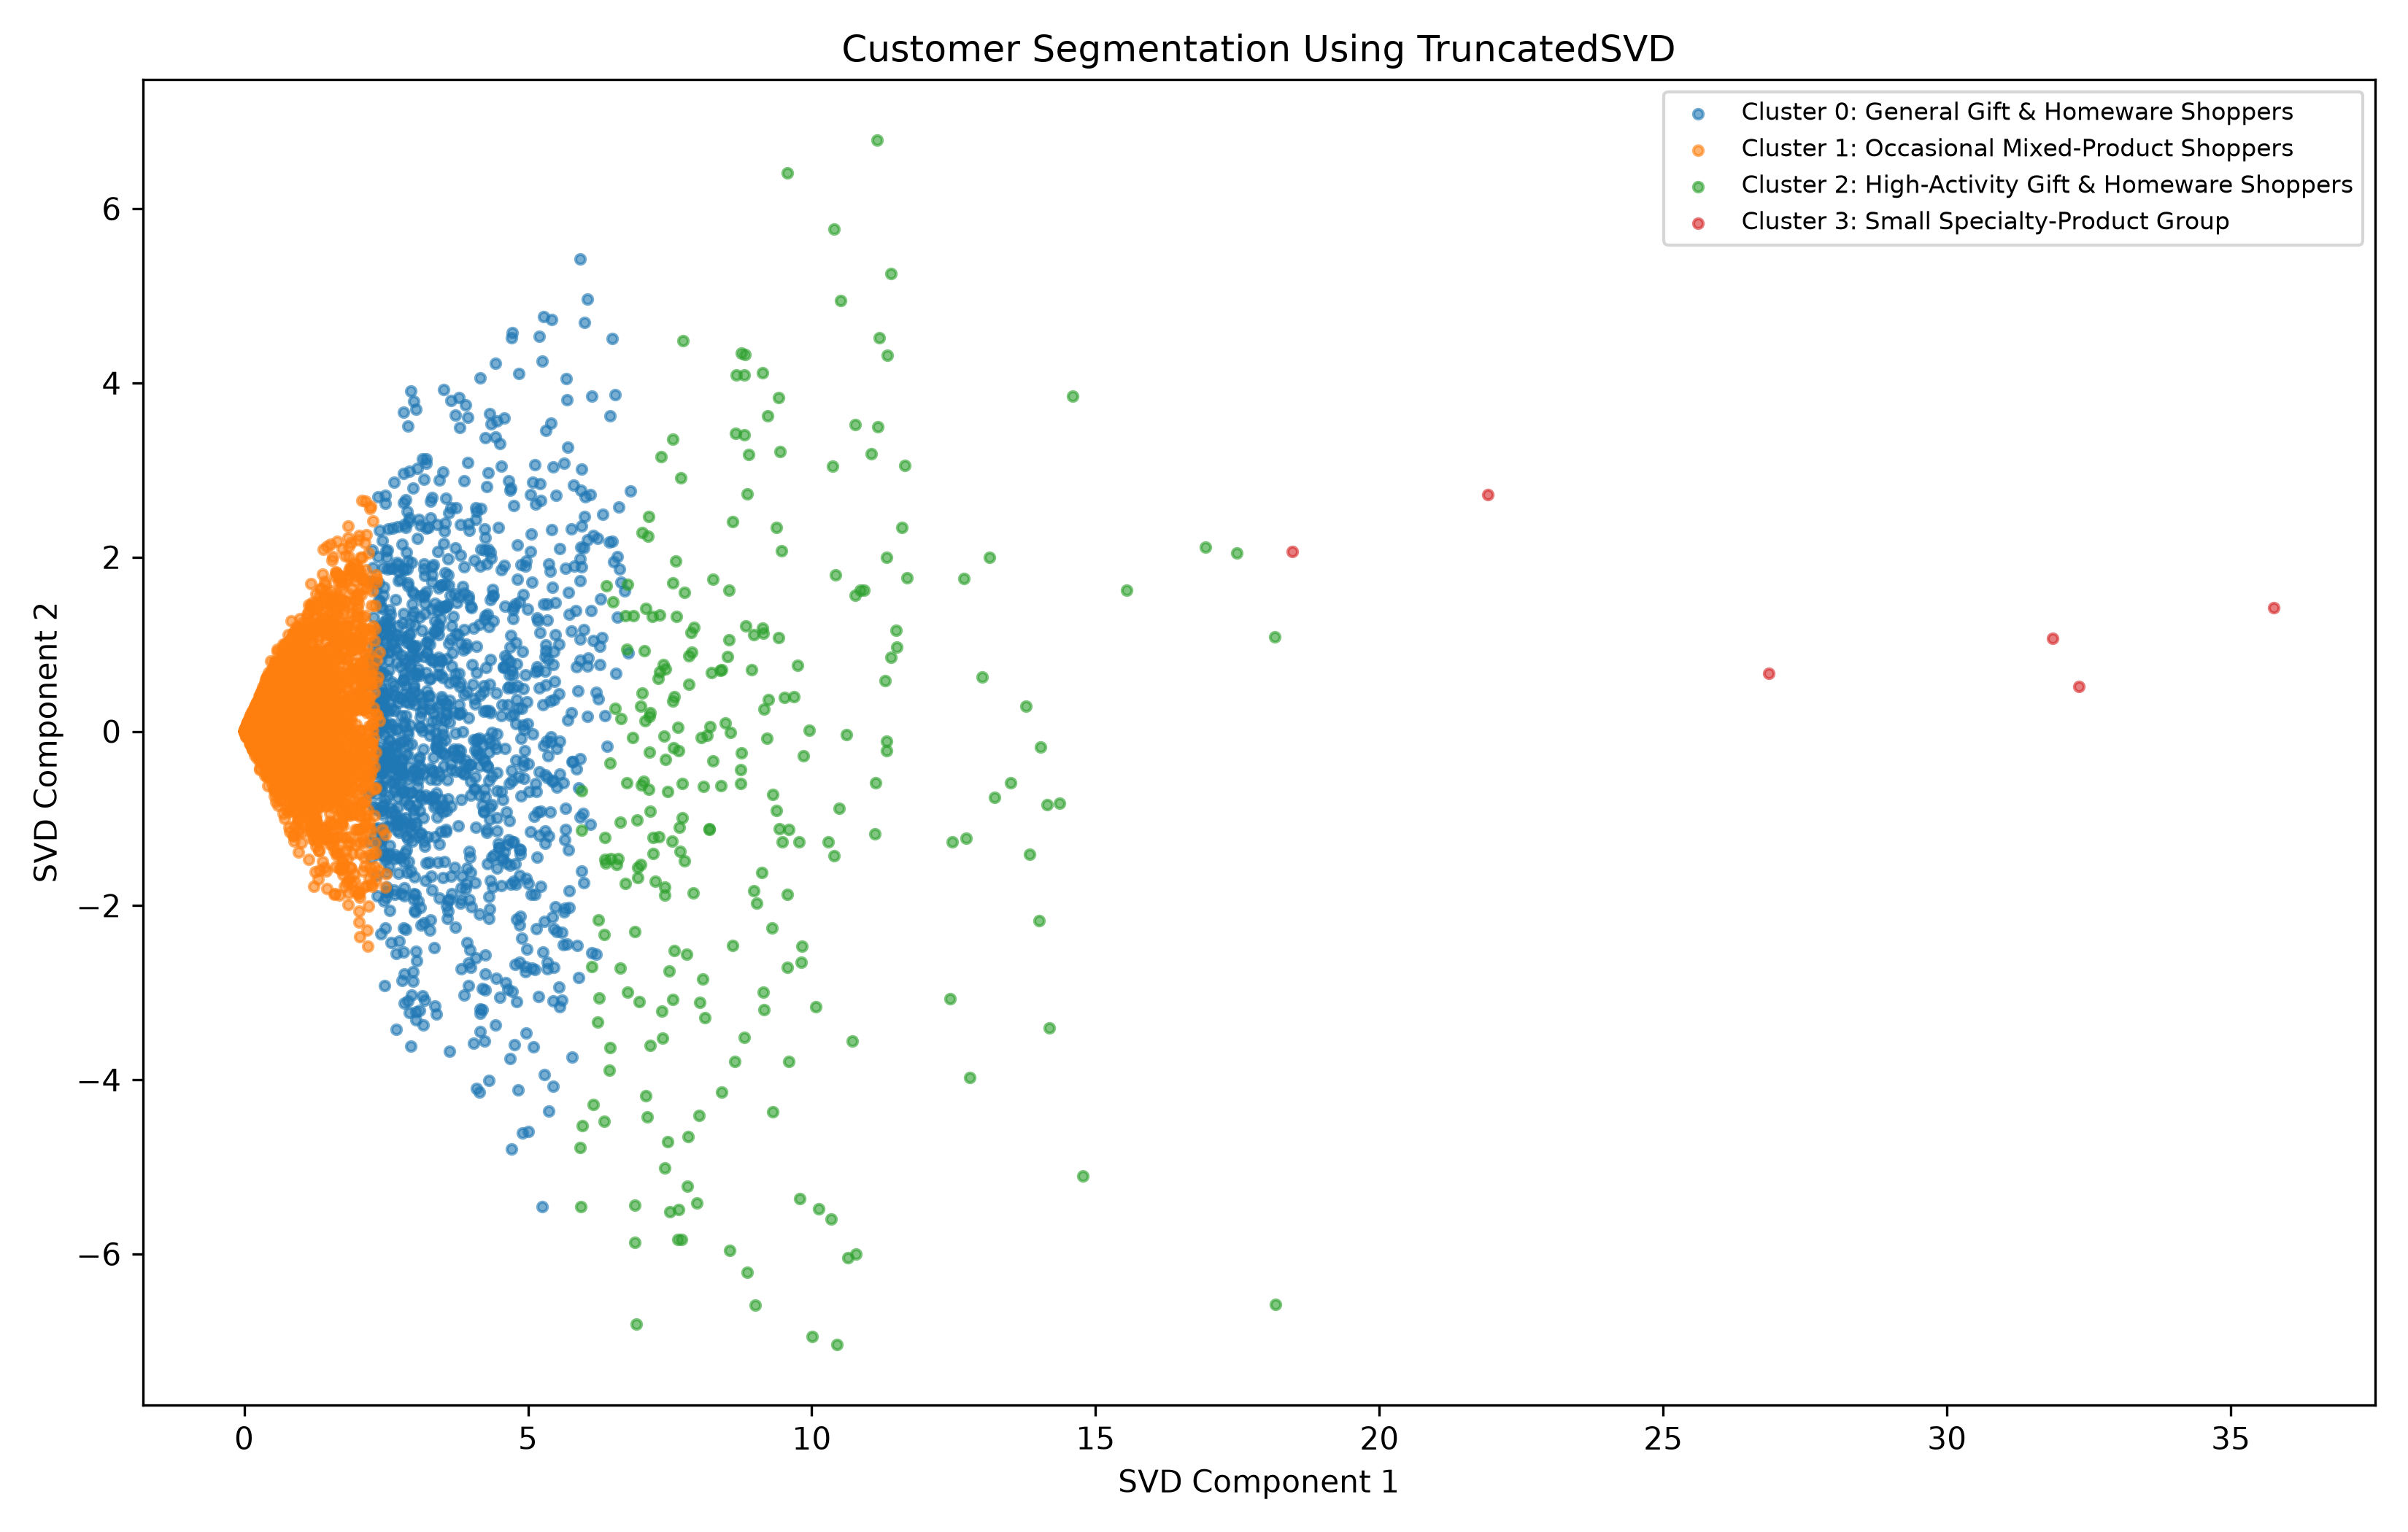

,Cluster,Segment Name,Customers
0,0,Regular Shoppers,1165
1,1,General Shoppers,4045
2,2,Concentrated Shoppers,258
3,3,Distinctive Shoppers,6


Total customers: 5474


In [7]:

print("Customer Segmentation: TruncatedSVD + K-Means")

display(Image(filename=str(output_dir / "customer_clusters.png")))

cluster_summary = pd.DataFrame({
    "Cluster": [0, 1, 2, 3],
    "Segment Name": [
        "Regular Shoppers",
        "General Shoppers",
        "Concentrated Shoppers",
        "Distinctive Shoppers"
    ],
    "Customers": [1165, 4045, 258, 6]
})

display(cluster_summary)

print("Total customers:", cluster_summary["Customers"].sum())
